# INSY 674 · LightGBM Modeling, Results and Interpretation

## 1. Import and Initial Preparation

Install lightgbm if it is not yet available; the other libraries are listed in requirements.txt.

In [1]:
# %pip install lightgbm

In [2]:
from pathlib import Path
import os

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
    make_scorer, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
    ConfusionMatrixDisplay)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [3]:
# Data files sit in the project folder, next to this notebook.
TRAIN_PATH = Path('train_raw.csv')
TEST_PATH = Path('test_raw.csv')

SEED = 42
N_SPLITS = 5
N_ITER = 30
THRESHOLD = 0.5
CPU = os.cpu_count() or 1
SEARCH_JOBS = min(N_SPLITS, CPU)
# parallel CV fits
LGBM_JOBS = max(1, CPU // SEARCH_JOBS)
# threads per LightGBM model, so the two layers do not oversubscribe
print(f'CPUs: {CPU} | parallel CV fits: {SEARCH_JOBS} | LightGBM threads per fit: {LGBM_JOBS}')

CPUs: 24 | parallel CV fits: 5 | LightGBM threads per fit: 4


In [4]:
TARGET = 'Revenue'
ID = 'source_row_id'
# Browsing behavior: page counts, time on pages, bounce/exit rates and page value
BROWSING = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
            'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues']
# Visit context: calendar, visitor type, device, region and traffic source
CONTEXT_NUMERIC = ['SpecialDay', 'Weekend']
CATEGORICAL = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
FEATURES = BROWSING + CONTEXT_NUMERIC + CATEGORICAL   # the same 17 raw predictors as XGBoost and the Random Forest

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

for name, df in [('train', train), ('test', test)]:
    missing_columns = sorted(set([ID, TARGET] + FEATURES) - set(df.columns))
    assert not missing_columns, f'{name} is missing columns: {missing_columns}'

shared_ids = set(train[ID]) & set(test[ID])
assert not shared_ids, 'Train and test share source_row_id values.'

display(pd.DataFrame({
    'rows': [len(train), len(test)],
    'missing values': [int(train.isna().sum().sum()), int(test.isna().sum().sum())],
    'purchases (Revenue = 1)': [int(train[TARGET].sum()), int(test[TARGET].sum())],
    'purchase rate': [round(train[TARGET].mean(), 4), round(test[TARGET].mean(), 4)],
}, index=['train', 'test']))
print('Shared source_row_id values between train and test:', len(shared_ids))

,rows,missing values,purchases (Revenue = 1),purchase rate
train,9764,0,1526,0.1563
test,2441,0,382,0.1565


Shared source_row_id values between train and test: 0


## 2. Preprocessing

The preprocessing follows the XGBoost notebook, so both boosting models get exactly the same inputs. source_row_id is only an ID, so we drop it, and Revenue is used as the target. Weekend is turned into 0/1. Month, VisitorType, OperatingSystems, Browser, Region and TrafficType are stored as numbers or text, but they are really labels (TrafficType = 10 is not "more" than TrafficType = 2), so we one-hot encode them. LightGBM can also handle categorical columns on its own, but we stay with one-hot encoding to keep the comparison with XGBoost fair. The encoder is part of the pipeline, which means it is fitted on the training part of each CV fold only.

In [5]:
for df in (train, test):
    df['Weekend'] = df['Weekend'].astype(int)
    df[CATEGORICAL] = df[CATEGORICAL].astype(str)

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]


ENGINEERED = ['TotalPages', 'TotalDuration', 'ProductPageShare', 'DurationPerPage']   # only for the check in Section 4


def make_model(include_pagevalues=True, engineered=False, **params):
    # Columns not listed here are left out (PageValues is dropped only for the sensitivity check).
    numeric = [c for c in BROWSING if include_pagevalues or c != 'PageValues'] + CONTEXT_NUMERIC
    if engineered:
        numeric = numeric + ENGINEERED
    preprocess = ColumnTransformer([
        ('numeric', 'passthrough', numeric),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL),
    ])
    # subsample_freq=1 makes the `subsample` setting take effect (row sampling for every tree)
    lgbm_model = lgb.LGBMClassifier(objective='binary', subsample_freq=1, random_state=SEED,
                                    n_jobs=LGBM_JOBS, verbose=-1, **params)
    return Pipeline([('preprocess', preprocess), ('lgbm', lgbm_model)])


print('Predictors:', len(FEATURES), '|', FEATURES)

Predictors: 17 | ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Weekend', 'Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


## 3. Baseline and Initial LightGBM

To compare LightGBM with the other models, we reuse the 5-fold stratified CV split on the training data (seed 42), which gives the same folds as in the XGBoost and Random Forest notebooks. Our main metric is average precision (AP). It looks at how well buyers are ranked above non-buyers, and a random model would get an AP around the purchase rate. Since only about 16% of sessions end in a purchase, AP tells us much more than accuracy. Precision, recall, F1 and accuracy are reported at a 0.5 threshold. We also report the AP on the training part of each fold (Train AP), because a big gap between train and validation AP is a sign of overfitting.

As a baseline we use a dummy model that always predicts the training purchase rate. The first LightGBM model just uses the library defaults: 100 trees, learning rate 0.1, 31 leaves per tree and no depth limit.

In [17]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
SCORING = {'AP': 'average_precision', 'ROC-AUC': 'roc_auc',
           'Precision': make_scorer(precision_score, zero_division=0), 'Recall': 'recall',
           'F1': make_scorer(f1_score, zero_division=0), 'Accuracy': 'accuracy'}


def mean_sd(fold_scores):
    # Mean ± sample standard deviation (ddof=1) over the five folds, as in the other model notebooks
    return f'{np.mean(fold_scores):.4f} ± {np.std(fold_scores, ddof=1):.4f}'


def cv_row(model, X=None):
    X = X_train if X is None else X
    scores = cross_validate(model, X, y_train, cv=cv, scoring=SCORING, n_jobs=SEARCH_JOBS, return_train_score=True)
    row = {m: mean_sd(scores['test_' + m]) for m in SCORING}
    row['Train AP'] = f"{scores['train_AP'].mean():.4f}"
    return row


cv_results = {
    'Baseline': cv_row(DummyClassifier(strategy='prior')),
    'Initial LightGBM': cv_row(make_model()),
}
display(pd.DataFrame(cv_results).T)

,AP,ROC-AUC,Precision,Recall,F1,Accuracy,Train AP
Baseline,0.1563 ± 0.0002,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.8437 ± 0.0002,0.1563
Initial LightGBM,0.7402 ± 0.0181,0.9268 ± 0.0049,0.7294 ± 0.0185,0.5990 ± 0.0179,0.6575 ± 0.0114,0.9025 ± 0.0034,0.9672


Even with default settings LightGBM is far ahead of the baseline: CV AP is 0.740 versus 0.156, and ROC-AUC is 0.927. So there is clearly useful information in the browsing and context variables. At 0.5 the model catches roughly 60% of buyers. Accuracy is 0.903, but this number does not say much here, because the baseline gets 0.844 just by predicting "no purchase" for everyone. Train AP is 0.967, much higher than the validation AP of 0.740, so the default model is overfitting quite a bit.

## 4. Quick Feature-Engineering Check

Next we test the four engineered features that were also tried in the Random Forest and XGBoost notebooks.The variable is shown below:

- TotalPages: administrative + informational + product pages
- TotalDuration: total time spent on the three page types
- ProductPageShare: ProductRelated / TotalPages
- DurationPerPage: TotalDuration / TotalPages

For the two ratios, sessions with 0 pages get a denominator of 1 so we do not divide by zero. 

In [7]:
pages = X_train['Administrative'] + X_train['Informational'] + X_train['ProductRelated']
X_train_eng = X_train.assign(
    TotalPages=pages,
    TotalDuration=X_train['Administrative_Duration'] + X_train['Informational_Duration'] + X_train['ProductRelated_Duration'],
)
X_train_eng['ProductPageShare'] = X_train_eng['ProductRelated'] / pages.replace(0, 1)
X_train_eng['DurationPerPage'] = X_train_eng['TotalDuration'] / pages.replace(0, 1)

feature_check = {
    'Initial LightGBM, raw features': cv_results['Initial LightGBM'],
    'Initial LightGBM, raw + 4 engineered features': cv_row(make_model(engineered=True), X_train_eng),
}
display(pd.DataFrame(feature_check).T[['AP', 'ROC-AUC', 'F1', 'Train AP']])

,AP,ROC-AUC,F1,Train AP
"Initial LightGBM, raw features",0.7402 ± 0.0181,0.9268 ± 0.0049,0.6575 ± 0.0114,0.9672
"Initial LightGBM, raw + 4 engineered features",0.7415 ± 0.0201,0.9283 ± 0.0059,0.6516 ± 0.0145,0.9765


The extra features barely change anything. AP moves from 0.740 to 0.742 and ROC-AUC from 0.927 to 0.928, while F1 goes down a little (0.658 to 0.652). These differences are tiny compared with the fold SD of about 0.02. Train AP also goes up from 0.967 to 0.977, so if anything the model overfits a bit more. We therefore drop the engineered features again. This is not too surprising, because the trees can already combine the page and duration columns through their splits.

## 5. Hyperparameter Tuning

LightGBM has many parameters that interact with each other, so instead of a full grid we use RandomizedSearchCV with 30 random combinations (the same number as for XGBoost). Each combination is scored by AP on the same five folds. We search over:

- n_estimators and learning_rate
- num_leaves, max_depth (-1 = no limit) and min_child_samples (minimum number of sessions in a leaf)
- subsample and colsample_bytree (row and column sampling)
- reg_alpha and reg_lambda (L1 and L2 penalties)
- scale_pos_weight (1 = no class weighting, or a weight based on the class ratio)

For LightGBM, num_leaves is the key setting. XGBoost grows its trees level by level and is mainly limited by max_depth, but LightGBM always splits the leaf with the largest gain first, so the number of leaves is what really controls how complex a tree gets. After the search, the best combination is refitted on the whole training set.

In [8]:
neg_pos = (y_train == 0).sum() / (y_train == 1).sum()   # from training labels only
param_distributions = {
    'lgbm__n_estimators': [100, 200, 300, 500, 800],
    'lgbm__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'lgbm__num_leaves': [7, 15, 31, 63],
    'lgbm__max_depth': [-1, 4, 6, 8],
    'lgbm__min_child_samples': [10, 20, 50, 100],
    'lgbm__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'lgbm__colsample_bytree': [0.5, 0.6, 0.7, 0.8, 1.0],
    'lgbm__reg_alpha': [0, 0.01, 0.1, 1],
    'lgbm__reg_lambda': [0, 0.5, 1, 5, 10],
    'lgbm__scale_pos_weight': [1, round(np.sqrt(neg_pos), 2), round(neg_pos, 2)],
}
search = RandomizedSearchCV(make_model(), param_distributions, n_iter=N_ITER, scoring=SCORING, refit='AP',
                            cv=cv, n_jobs=SEARCH_JOBS, random_state=SEED, return_train_score=True)
search.fit(X_train, y_train)
best_params = {k.replace('lgbm__', ''): v for k, v in search.best_params_.items()}

# Top 3 candidates by mean CV AP (one column per candidate)
results = pd.DataFrame(search.cv_results_).sort_values('rank_test_AP').head(3)
split_ap = results[[f'split{k}_test_AP' for k in range(N_SPLITS)]]
top3 = pd.concat([split_ap.mean(axis=1).rename('CV AP mean'), split_ap.std(axis=1, ddof=1).rename('CV AP SD'),
                  results[[c for c in results if c.startswith('param_')]]], axis=1)
top3.index = [f'rank {r}' for r in results['rank_test_AP']]
top3.columns = [c.replace('param_lgbm__', '') for c in top3.columns]
display(top3.T.round(4))

# Before vs after tuning, on the same folds
i = search.best_index_
cv_results['Tuned LightGBM'] = {m: mean_sd([search.cv_results_[f'split{k}_test_{m}'][i] for k in range(N_SPLITS)])
                                for m in SCORING}
cv_results['Tuned LightGBM']['Train AP'] = f"{search.cv_results_['mean_train_AP'][i]:.4f}"
display(pd.DataFrame(cv_results).T)

,rank 1,rank 2,rank 3
CV AP mean,0.7540,0.7534,0.7533
CV AP SD,0.0252,0.0267,0.0247
subsample,1.0000,0.7000,0.9000
scale_pos_weight,1.0000,2.3200,2.3200
reg_lambda,5.0000,1.0000,10.0000
reg_alpha,1.0000,0.0000,0.0100
num_leaves,31.0000,31.0000,31.0000
n_estimators,200.0000,800.0000,100.0000
min_child_samples,20.0000,10.0000,50.0000
max_depth,8.0000,4.0000,6.0000


,AP,ROC-AUC,Precision,Recall,F1,Accuracy,Train AP
Dummy (prior),0.1563 ± 0.0002,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.8437 ± 0.0002,0.1563
Initial LightGBM,0.7402 ± 0.0181,0.9268 ± 0.0049,0.7294 ± 0.0185,0.5990 ± 0.0179,0.6575 ± 0.0114,0.9025 ± 0.0034,0.9672
Tuned LightGBM,0.7540 ± 0.0252,0.9331 ± 0.0063,0.7388 ± 0.0108,0.5931 ± 0.0273,0.6577 ± 0.0184,0.9036 ± 0.0038,0.8679


After tuning, CV AP is 0.754 (up from 0.740) and ROC-AUC is 0.933 (up from 0.927). The bigger change is in overfitting: train AP drops from 0.967 to 0.868, so the gap to the validation score is much smaller now. The best model uses 200 trees with a lower learning rate of 0.03, a maximum depth of 8, 70% of the columns per tree and both L1 and L2 penalties (reg_alpha = 1, reg_lambda = 5). Still, the AP gain of 0.014 is smaller than the fold SD (about 0.025), so we would not say tuning made LightGBM much better. The default settings were already quite good. Recall at 0.5 also stays about the same (0.599 vs 0.593), which means around 40% of buyers are still missed.

The top three candidates all use 31 leaves, but otherwise they look quite different. For example, the best one has 200 trees with depth 8, while the second one has 800 trees with depth 4 and a learning rate of 0.01. Their AP values are within 0.001 of each other, so there is no single best setting and several combinations work about equally well. The best one does not use class weighting, but the second and third do (scale_pos_weight = 2.32) and score almost the same, so class weighting does not seem to matter much for AP here. Also, the best score was picked out of 30 tries on the same folds, so it is probably a bit too optimistic.

## 6. PageValues Sensitivity Check

PageValues comes from Google Analytics and is calculated from transaction revenue: it is the average value of the pages a user saw before a purchase. The dataset description does not say whether this value can already include the purchase made in the same session. If it can, the variable leaks the target. We cannot check this directly, so instead we measure how much LightGBM loses when PageValues is removed. The tuned parameters from Section 5 are reused, and the reduced model is not tuned again.

In [9]:
sensitivity = {
    'Tuned LightGBM, with PageValues (main model)': cv_results['Tuned LightGBM'],
    'Same parameters, without PageValues': cv_row(make_model(include_pagevalues=False, **best_params)),
}
display(pd.DataFrame(sensitivity).T[['AP', 'ROC-AUC', 'Recall', 'F1']])

,AP,ROC-AUC,Recall,F1
"Tuned LightGBM, with PageValues (main model)",0.7540 ± 0.0252,0.9331 ± 0.0063,0.5931 ± 0.0273,0.6577 ± 0.0184
"Same parameters, without PageValues",0.3786 ± 0.0218,0.7778 ± 0.0103,0.0832 ± 0.0111,0.1447 ± 0.0172


Removing PageValues cuts CV AP from 0.754 to 0.379, about half, and ROC-AUC goes from 0.933 to 0.778. At the 0.5 threshold recall falls to 8%, so the reduced model misses more than nine out of ten buyers. Most of LightGBM's performance therefore rests on this single column. This check only shows how dependent the model is; it cannot tell us whether PageValues is legitimate to use. If the variable does contain the session's own purchase, the scores in this notebook are higher than what browsing behavior alone could achieve.

## 7. Threshold and Final Evaluation

The 0.5 cut-off is only a default, so we also look for a better one. For this we use out-of-fold (OOF) predictions on the training set: each session gets its probability from the fold model that was trained without it. We scan thresholds from 0.05 to 0.95, keep the one with the highest F1 and compare it with 0.5. F1 weights precision and recall equally and ignores the real cost of a missed buyer or a false alarm, so the chosen threshold should not be read as a business recommendation. The test set plays no role in this step.

In [10]:
def metrics_at(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {'AP': average_precision_score(y_true, prob), 'ROC-AUC': roc_auc_score(y_true, prob),
            'Precision': precision_score(y_true, pred, zero_division=0), 'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred, zero_division=0), 'Accuracy': accuracy_score(y_true, pred),
            'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}


oof = cross_val_predict(make_model(**best_params), X_train, y_train, cv=cv, method='predict_proba',
                        n_jobs=SEARCH_JOBS)[:, 1]
candidate_thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
oof_f1 = [f1_score(y_train, (oof >= t).astype(int), zero_division=0) for t in candidate_thresholds]
CHOSEN_THRESHOLD = float(candidate_thresholds[np.argmax(oof_f1)])

display(pd.DataFrame({f'Training OOF, threshold {t:.2f}': metrics_at(y_train, oof, t)
                      for t in [THRESHOLD, CHOSEN_THRESHOLD]}).T.round(4))

,AP,ROC-AUC,Precision,Recall,F1,Accuracy,TN,FP,FN,TP
"Training OOF, threshold 0.50",0.7524,0.9328,0.7388,0.5931,0.6579,0.9036,7918.0,320.0,621.0,905.0
"Training OOF, threshold 0.34",0.7524,0.9328,0.6594,0.7307,0.6932,0.8989,7662.0,576.0,411.0,1115.0


F1 is highest at a threshold of 0.34. Going from 0.5 down to 0.34 lifts OOF recall from 0.59 to 0.73, but the number of false positives grows from 320 to 576, so the net gain in F1 is small (0.66 to 0.69).

With both thresholds (0.5 and 0.34) set in advance, the tuned model is refitted on the full training set and the test set is scored a single time.

,AP,ROC-AUC,Precision,Recall,F1,Accuracy,TN,FP,FN,TP
Dummy (prior),0.1565,0.5000,0.0000,0.0000,0.0000,0.8435,2059.0,0.0,382.0,0.0
"Tuned LightGBM, threshold 0.50",0.7569,0.9366,0.7358,0.6126,0.6686,0.9050,1975.0,84.0,148.0,234.0
"Tuned LightGBM, threshold 0.34",0.7569,0.9366,0.6525,0.7225,0.6857,0.8964,1912.0,147.0,106.0,276.0


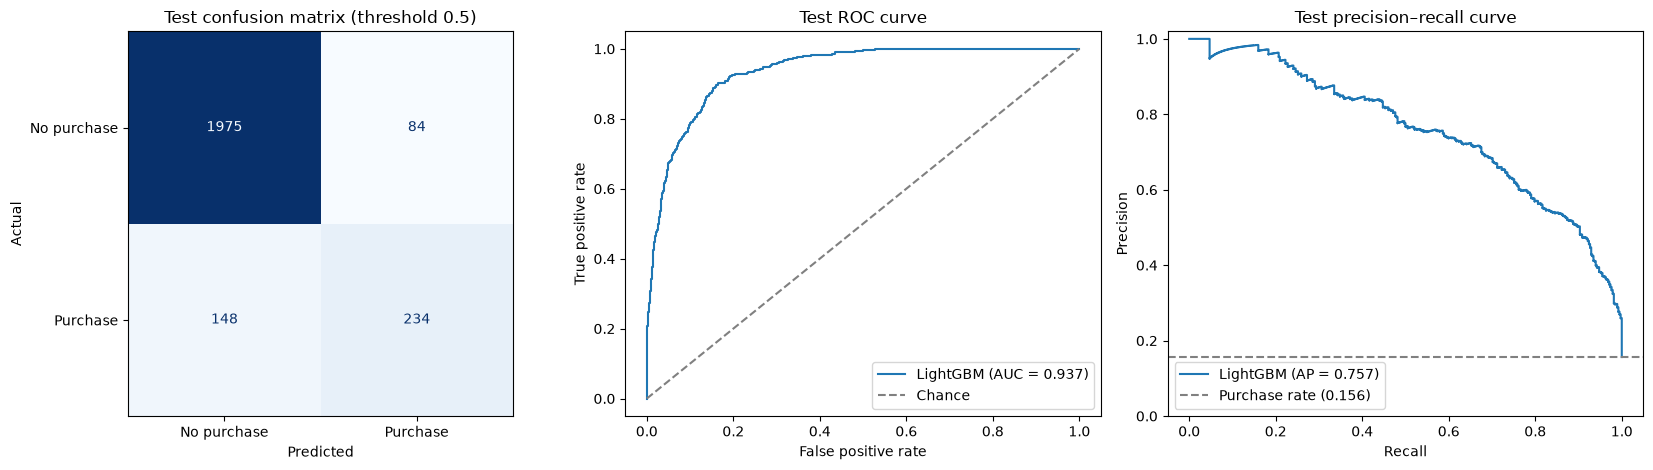

In [11]:
final_model = search.best_estimator_
p_test = final_model.predict_proba(X_test)[:, 1]
p_dummy = DummyClassifier(strategy='prior').fit(X_train, y_train).predict_proba(X_test)[:, 1]

display(pd.DataFrame({
    'Baseline (Dummy)': metrics_at(y_test, p_dummy, THRESHOLD),
    'Tuned LightGBM, threshold 0.50': metrics_at(y_test, p_test, THRESHOLD),
    f'Tuned LightGBM, threshold {CHOSEN_THRESHOLD:.2f}': metrics_at(y_test, p_test, CHOSEN_THRESHOLD),
}).T.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, (p_test >= THRESHOLD).astype(int),
                                        display_labels=['No purchase', 'Purchase'], ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set(title=f'Test confusion matrix (threshold {THRESHOLD})', xlabel='Predicted', ylabel='Actual')

fpr, tpr, _ = roc_curve(y_test, p_test)
axes[1].plot(fpr, tpr, label=f'LightGBM (AUC = {roc_auc_score(y_test, p_test):.3f})')
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Chance')
axes[1].set(title='Test ROC curve', xlabel='False positive rate', ylabel='True positive rate')
axes[1].legend(loc='lower right')

precision, recall, _ = precision_recall_curve(y_test, p_test)
axes[2].step(recall, precision, where='post', label=f'LightGBM (AP = {average_precision_score(y_test, p_test):.3f})')
axes[2].axhline(y_test.mean(), ls='--', color='gray', label=f'Purchase rate ({y_test.mean():.3f})')
axes[2].set(title='Test precision–recall curve', xlabel='Recall', ylabel='Precision', ylim=(0, 1.02))
axes[2].legend(loc='lower left')
fig.tight_layout(); plt.show(); plt.close(fig)

The test AP is 0.757 and the test ROC-AUC is 0.937, very close to the CV estimates of 0.754 and 0.933, so the model generalizes well to sessions it was not trained on. One caveat is that the test set is a random sample of the same data, so it does not show how the model would do on traffic from a later period.

At 0.5, LightGBM catches 234 of the 382 buyers in the test set (recall 61%) with a precision of 74%. That leaves 148 buyers undetected and 84 non-buyers flagged by mistake. Moving to 0.34 raises the number of detected buyers to 276, at the price of 147 false positives instead of 84; F1 rises only from 0.669 to 0.686.

In the ROC plot the curve stays well above the diagonal (AUC 0.937 vs 0.5), and in the precision–recall plot the AP of 0.757 is far above the purchase rate of 0.156 shown by the dashed line. The group comparison uses the 0.5 results.

## 8. Feature Importance and Error Analysis

To see which inputs LightGBM relies on, we use permutation importance on the CV validation folds. Within each fold, one original variable is shuffled at a time (five repeats) and the resulting drop in AP is recorded; the plot shows the average over the five folds. A categorical variable is shuffled as a single column, so all of its one-hot columns change together.

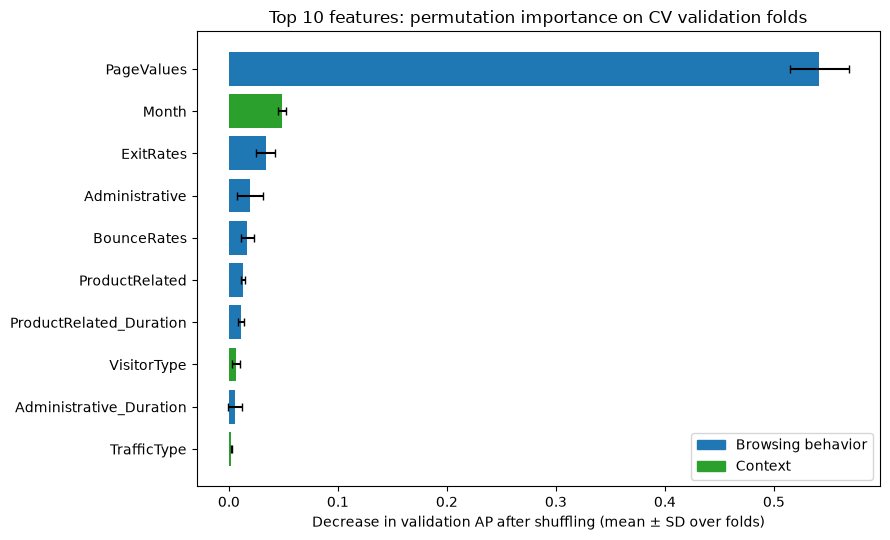

,AP drop (mean over folds),SD over folds,group
PageValues,0.5416,0.0272,browsing behavior
Month,0.0488,0.0037,context
ExitRates,0.0339,0.0087,browsing behavior
Administrative,0.0195,0.0118,browsing behavior
BounceRates,0.0171,0.0060,browsing behavior
ProductRelated,0.0130,0.0022,browsing behavior
ProductRelated_Duration,0.0109,0.0030,browsing behavior
VisitorType,0.0064,0.0037,context
Administrative_Duration,0.0056,0.0068,browsing behavior
TrafficType,0.0023,0.0005,context


In [12]:
fold_importance = []
for train_idx, val_idx in cv.split(X_train, y_train):
    model = make_model(**best_params).fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    result = permutation_importance(model, X_train.iloc[val_idx], y_train.iloc[val_idx],
                                    scoring='average_precision', n_repeats=5, random_state=SEED)
    fold_importance.append(result.importances_mean)

importance = pd.DataFrame({'AP drop (mean over folds)': np.mean(fold_importance, axis=0),
                           'SD over folds': np.std(fold_importance, axis=0, ddof=1)}, index=FEATURES)
importance['group'] = ['browsing behavior' if f in BROWSING else 'context' for f in FEATURES]
top10 = importance.sort_values('AP drop (mean over folds)', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_data = top10.iloc[::-1]
ax.barh(plot_data.index, plot_data['AP drop (mean over folds)'], xerr=plot_data['SD over folds'], capsize=3,
        color=['tab:blue' if g == 'browsing behavior' else 'tab:green' for g in plot_data['group']])
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ['tab:blue', 'tab:green']],
          labels=['Browsing behavior', 'Context'], loc='lower right')
ax.set(title='Top 10 features: permutation importance on CV validation folds',
       xlabel='Decrease in validation AP after shuffling (mean ± SD over folds)')
fig.tight_layout(); plt.show(); plt.close(fig)
display(top10.round(4))

PageValues dominates: shuffling it reduces AP by 0.54, roughly eleven times the effect of any other variable. Next come Month (0.049) and ExitRates (0.034), then Administrative, BounceRates, ProductRelated and ProductRelated_Duration.

Grouped by type, the browsing variables matter most, led by page value and followed by exit rate, administrative visits, bounce rate and product-page activity. On the context side, Month is the only variable with a clear effect, and VisitorType and TrafficType help slightly. Weekend, special day, operating system, browser, region and the informational-page variables have very little influence on this model.

These numbers describe how much LightGBM uses each variable for its predictions. They do not measure cause and effect, and they do not say whether a higher value makes a purchase more or less likely. Since PageValues is correlated with several other browsing variables, part of their information is already covered by it, which can make them look less important here.

The table below splits the training OOF predictions at the 0.5 threshold into correct and incorrect groups.

In [13]:
oof_pred = (oof >= THRESHOLD).astype(int)
train['outcome'] = np.select(
    [(y_train == 1) & (oof_pred == 1), (y_train == 1) & (oof_pred == 0), (y_train == 0) & (oof_pred == 1)],
    ['true positive', 'false negative (missed buyer)', 'false positive (false alarm)'], default='true negative')

error_table = train.groupby('outcome').agg(
    sessions=(TARGET, 'size'),
    median_page_value=('PageValues', 'median'),
    median_product_pages=('ProductRelated', 'median'),
    median_product_duration=('ProductRelated_Duration', 'median'),
    median_exit_rate=('ExitRates', 'median'),
)
display(error_table.round(3))

,sessions,median_page_value,median_product_pages,median_product_duration,median_exit_rate
outcome,,,,,
false negative (missed buyer),621,1.452,37.0,1462.659,0.022
false positive (false alarm),320,19.725,32.5,1220.865,0.016
true negative,7918,0.000,16.0,496.574,0.029
true positive,905,31.980,24.0,936.833,0.013


The 621 missed buyers look very different from the buyers the model catches: their median page value is only 1.5 against 32.0, even though they viewed more product pages (37 vs 24). The 320 false alarms are the opposite case. Their median page value is fairly high (19.7) and they viewed about twice as many product pages as the true negatives (32.5 vs 16), yet they did not buy. Most errors therefore happen when PageValues gives a misleading signal and the remaining variables are not strong enough to correct it. Data such as add-to-cart actions, prices or promotions, which are not in the dataset, would probably be needed to separate these cases.

## 9. Conclusion and Limitations

LightGBM is a large improvement over the baseline. Its test AP is 0.757 against 0.156 for the baseline, its ROC-AUC is 0.937, and at the 0.5 threshold it identifies 61% of buyers with a precision of 74%. Most of this was already achieved by the default model. Tuning added only a small AP gain, but it narrowed the gap between train and validation AP considerably (from 0.967 vs 0.740 to 0.868 vs 0.754), and the four engineered features made no difference.

Page value is clearly the strongest browsing signal, ahead of exit rate, administrative visits, bounce rate and product-page activity. Among the context variables only Month stands out.

The biggest concern is PageValues. Without it AP falls by about half, and because we cannot verify that it excludes the session's own purchase, some of the performance may be due to leakage. Timing is another issue: each row summarizes a session that has already ended, so we have only shown that the model can classify finished sessions, not that it can predict a purchase while the visit is still in progress.

Other limitations:

- Purchases make up only about 16% of the sessions, and at 0.5 roughly four in ten buyers are missed.
- The 0.34 threshold maximizes F1 and is not based on the actual costs of errors.
- The tuned model's CV score is the best of 30 candidates evaluated on the same folds, so it is likely slightly inflated.
- All sessions come from one year, so we cannot check whether the patterns hold in other years.

The table below summarizes the results used in the group comparison (CV mean ± SD across the five folds, and test metrics at the 0.5 threshold).

In [14]:
group_summary = {'CV ' + m: cv_results['Tuned LightGBM'][m] for m in ['AP', 'ROC-AUC', 'F1']}
test_at_05 = metrics_at(y_test, p_test, THRESHOLD)
group_summary.update({'Test ' + m: round(test_at_05[m], 4) for m in ['AP', 'ROC-AUC', 'Precision', 'Recall', 'F1', 'Accuracy']})
display(pd.DataFrame(group_summary, index=['LightGBM (tuned, 17 raw features)']).T)

,"LightGBM (tuned, 17 raw features)"
CV AP,0.7540 ± 0.0252
CV ROC-AUC,0.9331 ± 0.0063
CV F1,0.6577 ± 0.0184
Test AP,0.7569
Test ROC-AUC,0.9366
Test Precision,0.7358
Test Recall,0.6126
Test F1,0.6686
Test Accuracy,0.905
